In [ ]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(__file__), '..')))

import joblib
import pandas as pd
import numpy as np
import pandas_ta as ta
import matplotlib.pyplot as plt
from trades_from_signal import get_trades_from_signal
from utils import price_dict_to_df
plt.style.use('dark_background')

In [ ]:
def cmma(ohlc: pd.DataFrame, lookback: int, atr_lookback: int = 30):
    """
    Close minus moving average, normalized by ATR * sqrt(lookback)
    """
    atr = ta.atr(ohlc['high'], ohlc['low'], ohlc['close'], atr_lookback)
    ma = ohlc['close'].rolling(lookback).mean()
    ind = (ohlc['close'] - ma) / (atr * np.sqrt(lookback))
    return ind

def threshold_revert_signal(ind: pd.Series, threshold: float):
    # Outputs a 1 or -1 signal once the indicator goes above threshold or below -threshold
    # Outputs 0 again once the indicator returns to 0

    signal = np.zeros(len(ind))
    position = 0
    for i in range(len(ind)):
        if ind.iloc[i] > threshold:
            position = 1
        if ind.iloc[i] < -threshold:
            position = -1

        if position == 1 and ind.iloc[i] <= 0:
            position = 0
        
        if position == -1 and ind.iloc[i] >= 0:
            position = 0

        signal[i] = position
    
    return signal

def pair_trade_backtest(data1, data2,
                        signal=None,
                        lookback=60,
                        threshold=0.15,
                        atr_lookback=10,
                        lookback_hr=100,
                        pair_trade=True,
                        mode=('long', 'short'),   # NEW
                        fee_rate=0.001, plot=False):
    """
    Runs a pair trading backtest on two assets or uses a provided signal.

    Parameters:
    -----------
    mode : tuple(str, str)
        Direction for (data2, data1). Each value can be 'long' or 'short'.
        Example:
            ('long', 'short') -> long data2, short data1 (default)
            ('long', 'long')  -> long both assets
            ('short', 'short') -> short both assets
            ('short', 'long')  -> short data2, long data1
    """

    # --------------------------
    # Align data
    # --------------------------
    if 'open_time' in data1.columns:
        data1 = data1.set_index('open_time')
    if 'open_time' in data2.columns:
        data2 = data2.set_index('open_time')

    common_index = data1.index.intersection(data2.index)
    data1 = data1.reindex(common_index)
    data2 = data2.reindex(common_index)

    # Compute log returns
    for df in [data1, data2]:
        df['rets'] = np.log(df['close']).diff()
        df['next_return'] = df['rets'].shift(-1)

    # --------------------------
    # Signal
    # --------------------------
    if signal is not None:
        data2['sig'] = signal.reindex(data2.index).fillna(0)
        data1['sig'] = -data2['sig']
    else:
        cmma_1 = cmma(data1, lookback, atr_lookback)
        cmma_2 = cmma(data2, lookback, atr_lookback)
        intermarket_diff = cmma_2 - cmma_1
        data2['sig'] = threshold_revert_signal(intermarket_diff, threshold)
        data1['sig'] = -data2['sig']

    # --------------------------
    # Hedge ratio = beta
    # --------------------------
    mean_1 = data1['rets'].rolling(lookback_hr).mean()
    mean_2 = data2['rets'].rolling(lookback_hr).mean()

    cov_12 = ((data2['rets'] - mean_2) *
              (data1['rets'] - mean_1)).rolling(lookback_hr).mean()
    var_1 = (data1['rets'] - mean_1).pow(2).rolling(lookback_hr).mean()
    hedge_ratio = (cov_12 / var_1).bfill()

    if pair_trade:
        data1['sig'] = data2['sig'] * hedge_ratio
        # Apply mode direction
        if mode[0] == 'short':
            data2['sig'] *= -1
        if mode[1] == 'short':
            data1['sig'] *= -1
    else:
        data1['sig'] = 0

    # --------------------------
    # PnL calculation
    # --------------------------
    pnl_data2 = data2['sig'] * data2['next_return']
    pnl_data1 = data1['sig'] * data1['next_return'] if pair_trade else 0
    rets = pnl_data2 + (pnl_data1 if pair_trade else 0)

    rets = rets.reindex(common_index)
    rets = rets.fillna(0)

    # --------------------------
    # Stats
    # --------------------------

    # Performance
    gross_profit = rets[rets > 0].sum()
    gross_loss = abs(rets[rets < 0].sum())
    pf = gross_profit / gross_loss if gross_loss > 0 else np.nan

    # --------------------------
    # Plot cumulative returns
    # --------------------------
    if plot:
        plt.figure(figsize=(12, 5))
        if pair_trade:
            plt.plot(pnl_data2.cumsum(), label=f"PnL Data2 ({mode[0]})")
            plt.plot(pnl_data1.cumsum(), label=f"PnL Data1 ({mode[1]})")
        plt.plot(rets.cumsum(), label="Total Portfolio", linewidth=2, color='white')
        plt.ylabel("Cumulative Log Return")
        plt.title("Pair Trade Performance" if pair_trade else "Single Asset Trade")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

    # --------------------------
    # Trades statistics
    # --------------------------
    long_trades, short_trades, all_trades = get_trades_from_signal(data2, data2['sig'], fee_rate)

    stats = {}
    for name, trades in zip(["Long", "Short"], [long_trades, short_trades]):
        tr = trades['return']
        win_rate = len(tr[tr > 0]) / len(tr) if len(tr) > 0 else 0
        avg_return = tr.mean() * 100 if len(tr) > 0 else 0
        sharpe = tr.mean() / tr.std() * np.sqrt(365) if len(tr) > 0 and tr.std() > 0 else 0
        stats[name] = {
            "num_trades": len(tr),
            "win_rate": round(win_rate, 2),
            "avg_trade_pct": round(avg_return, 3),
            "sharpe_ratio": round(sharpe, 3)
        }

    return {
        "profit_factor": round(pf, 4),
        "returns": rets,
        "pnl_leg1": pnl_data1,
        "pnl_leg2": pnl_data2,
        "stats": stats,
        "long_trades": long_trades,
        "short_trades": short_trades,
        "all_trades": all_trades
    }

In [ ]:
datas = joblib.load('/Users/leoinv/Documents/CODE/BACKTEST/data/1h.joblib')
close = price_dict_to_df(datas)
close = close.ffill()

min_valid_rows = 40000
close = close.loc[:, close.notna().sum() >= min_valid_rows]
close = close.dropna()
rets = np.log(close).diff().dropna()

split_idx = int(len(rets.index) * 0.8)
train_to = rets.index[split_idx]
test_fr = train_to

# Compute Kendall tau correlation matrix
corr_matrix_kendall = rets[: train_to].corr('kendall') 

# Extract upper triangle pairs
corr_pairs_kendall = (
    corr_matrix_kendall
    .where(np.triu(np.ones(corr_matrix_kendall.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
corr_pairs_kendall.columns = ["Asset1", "Asset2", "Corr"]

Data is ready


In [ ]:
# Get top correlated pairs
top_pairs = corr_pairs_kendall[corr_pairs_kendall["Corr"] >= 0.1]
top_pairs = top_pairs[
    top_pairs['Asset1'].str.contains('BTCUSDT') | top_pairs['Asset2'].str.contains('BTCUSDT')
]

result = {}
for symbol1, symbol2 in zip(top_pairs['Asset1'], top_pairs['Asset2']):
    result[(symbol1, symbol2)] = {}

    data1 = datas[symbol1]
    data2 = datas[symbol2]
    
    if 'open_time' in data1.columns:
        data1.set_index('open_time', inplace=True)
    if 'open_time' in data2.columns:
        data2.set_index('open_time', inplace=True)

    data1 = data1.loc[:train_to]
    data2 = data2.loc[:train_to]

    res = pair_trade_backtest(data1, data2, mode=['long', 'short'], pair_trade=True, plot=False)

    result[(symbol1, symbol2)] = res['returns']
    
strat_rets = pd.DataFrame(result).fillna(0)

sharpe = strat_rets.mean() / strat_rets.std() * np.sqrt(365 * 24)
gross_profit = strat_rets[strat_rets > 0].sum()
gross_loss = abs(strat_rets[strat_rets < 0].sum())
profit_factor = gross_profit / gross_loss

sharpe_df = pd.DataFrame(
    [(k[0], k[1], v) for k, v in sharpe.to_dict().items()],
    columns=['Asset1', 'Asset2', 'Sharpe']
)
pf_df = pd.DataFrame(
    [(k[0], k[1], v) for k, v in profit_factor.to_dict().items()],
    columns=['Asset1', 'Asset2', 'ProfitFactor']
)

corr_pairs_kendall = corr_pairs_kendall.rename(columns={"Kendall_Tau": "Corr"})
merged = (
    pd.merge(corr_pairs_kendall, sharpe_df, on=['Asset1', 'Asset2'], how='inner')
    .merge(pf_df, on=['Asset1', 'Asset2'], how='inner')
)

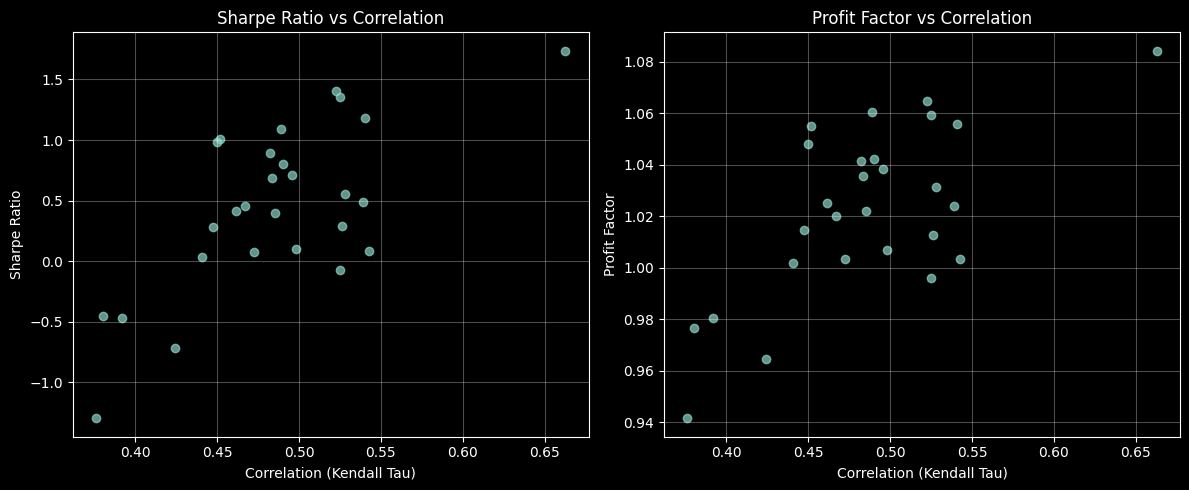

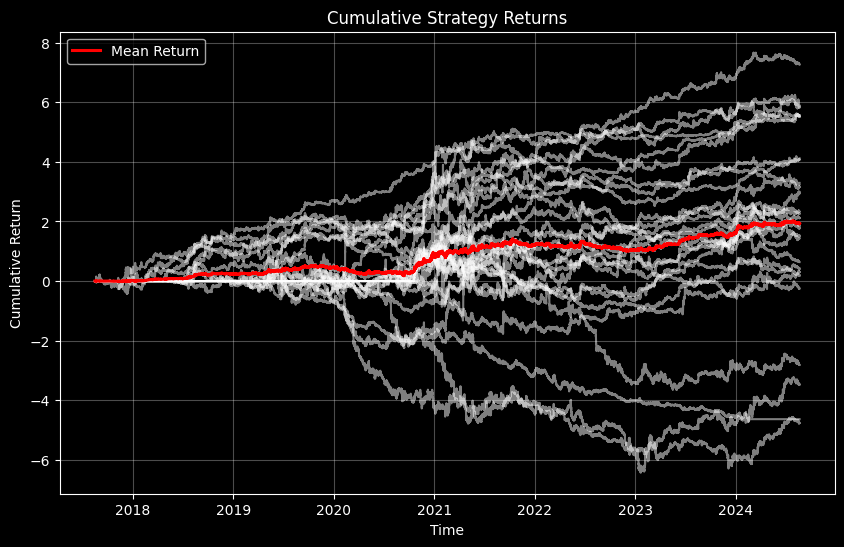

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(merged['Corr'], merged['Sharpe'], alpha=0.7)
plt.xlabel('Correlation (Kendall Tau)')
plt.ylabel('Sharpe Ratio')
plt.title('Sharpe Ratio vs Correlation')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(merged['Corr'], merged['ProfitFactor'], alpha=0.7)
plt.xlabel('Correlation (Kendall Tau)')
plt.ylabel('Profit Factor')
plt.title('Profit Factor vs Correlation')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot cumulative returns
cum_strat_rets = strat_rets.cumsum()
plt.figure(figsize=(10, 6))

if isinstance(cum_strat_rets, pd.Series):
    plt.plot(cum_strat_rets, color='white', label='Strategy')
else:
    for col in cum_strat_rets.columns:
        plt.plot(cum_strat_rets.index, cum_strat_rets[col], color='white', alpha=0.5)
    plt.plot(cum_strat_rets.index, cum_strat_rets.mean(axis=1), 
             label="Mean Return", linewidth=2.2, color='red')

plt.title("Cumulative Strategy Returns", color='white')
plt.xlabel("Time", color='white')
plt.ylabel("Cumulative Return", color='white')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

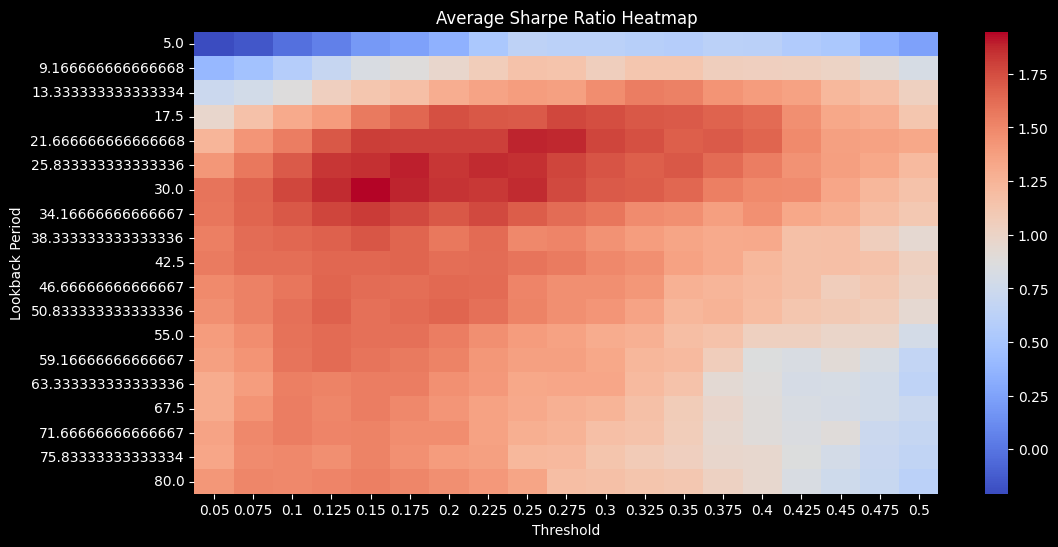

In [ ]:
import seaborn as sns

top = sharpe_df.sort_values('Sharpe', ascending=False).nlargest(3, 'Sharpe')

heatmaps = []
for asset1, asset2 in zip(top['Asset1'], top['Asset2']):
    data1 = datas[asset1][:train_to]
    data2 = datas[asset2][:train_to]
    
    sh_df = pd.DataFrame()

    for lb in np.linspace(5, 80, 19):
        for th in np.linspace(0.05, 0.5, 19):
            res = pair_trade_backtest(
                data1, data2,
                lookback=int(lb),
                threshold=th,
                atr_lookback=10,
                lookback_hr=100,
                pair_trade=True,
                mode=('long', 'short'),
                fee_rate=.001,
                plot=False
            )
            rets = res['returns']
            sh_df.loc[lb, round(th, 3)] = rets.mean() / rets.std() * np.sqrt(365 * 24)

    heatmaps.append(sh_df)

# Average as before
all_heatmaps = pd.concat(heatmaps, keys=range(len(heatmaps)))
avg_heatmap = all_heatmaps.groupby(level=1).mean()

plt.figure(figsize=(12, 6))
sns.heatmap(avg_heatmap, annot=False, fmt='0.3g', cmap='coolwarm')
plt.xlabel('Threshold')
plt.ylabel('Lookback Period')
plt.title('Average Sharpe Ratio Heatmap')
plt.show()

In [ ]:
"""
Optimum params:
Corr >= 0.45
Lookback = [20 - 30]
Threshold = [0.15 - 0.25]
"""

test_pairs = corr_pairs_kendall[corr_pairs_kendall["Corr"] >= 0.45]
test_pairs = test_pairs[
    test_pairs['Asset1'].str.contains('BTCUSDT') | test_pairs['Asset2'].str.contains('BTCUSDT')
]

result = {}
for symbol1, symbol2 in zip(test_pairs['Asset1'], test_pairs['Asset2']):
    result[(symbol1, symbol2)] = {}

    data1 = datas[symbol1]
    data2 = datas[symbol2]
    
    if 'open_time' in data1.columns:
        data1.set_index('open_time', inplace=True)
    if 'open_time' in data2.columns:
        data2.set_index('open_time', inplace=True)

    data1 = data1.loc[test_fr:]
    data2 = data2.loc[test_fr:]

    res = pair_trade_backtest(data1, data2, mode=['long', 'short'], pair_trade=True, plot=False,
                              lookback=30, threshold=0.15, fee_rate=0.001)

    result[(symbol1, symbol2)] = res['returns']
    
strat_rets = pd.DataFrame(result).fillna(0)

sharpe = strat_rets.mean() / strat_rets.std() * np.sqrt(365 * 24)
gross_profit = strat_rets[strat_rets > 0].sum()
gross_loss = abs(strat_rets[strat_rets < 0].sum())
profit_factor = gross_profit / gross_loss

sharpe_df = pd.DataFrame(
    [(k[0], k[1], v) for k, v in sharpe.to_dict().items()],
    columns=['Asset1', 'Asset2', 'Sharpe']
)
pf_df = pd.DataFrame(
    [(k[0], k[1], v) for k, v in profit_factor.to_dict().items()],
    columns=['Asset1', 'Asset2', 'ProfitFactor']
)

corr_pairs_kendall = corr_pairs_kendall.rename(columns={"Kendall_Tau": "Corr"})
merged = (
    pd.merge(corr_pairs_kendall, sharpe_df, on=['Asset1', 'Asset2'], how='inner')
    .merge(pf_df, on=['Asset1', 'Asset2'], how='inner')
)

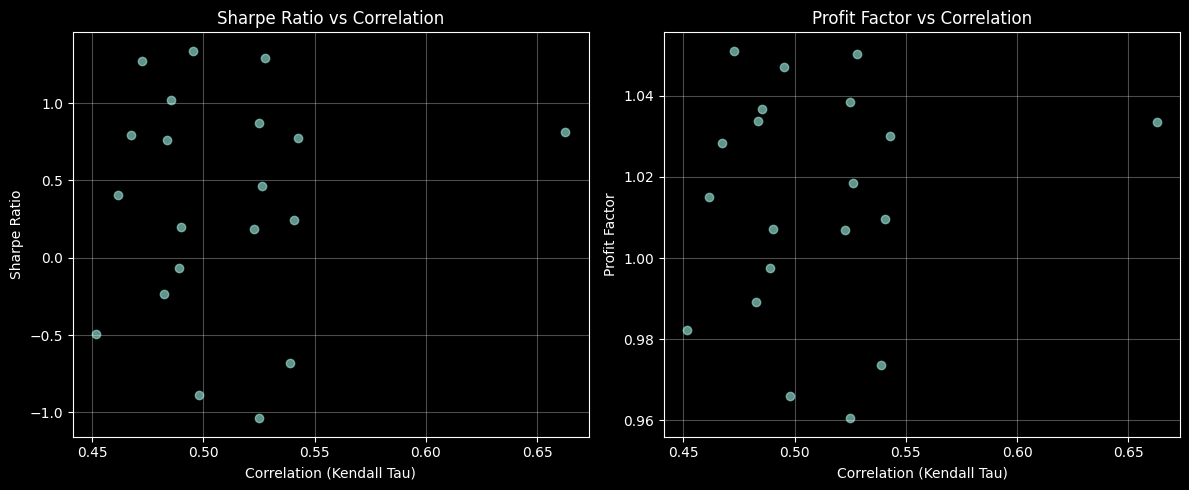

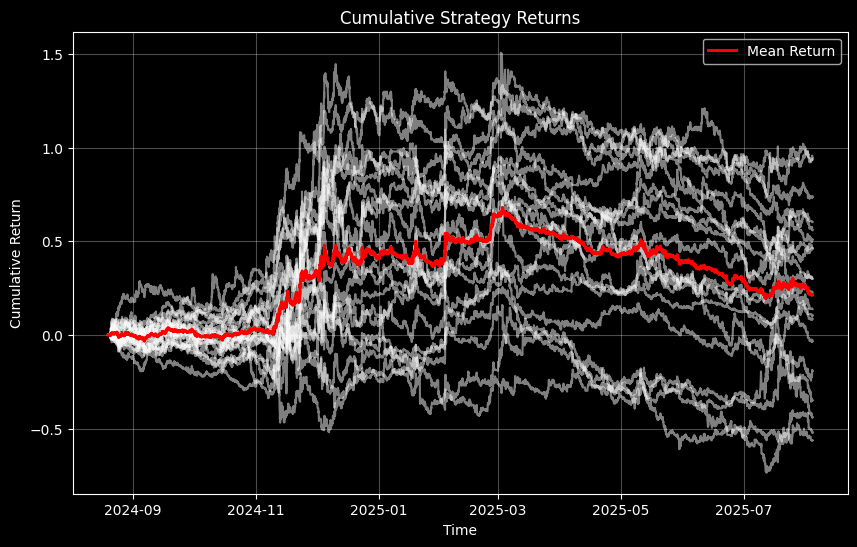

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(merged['Corr'], merged['Sharpe'], alpha=0.7)
plt.xlabel('Correlation (Kendall Tau)')
plt.ylabel('Sharpe Ratio')
plt.title('Sharpe Ratio vs Correlation')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(merged['Corr'], merged['ProfitFactor'], alpha=0.7)
plt.xlabel('Correlation (Kendall Tau)')
plt.ylabel('Profit Factor')
plt.title('Profit Factor vs Correlation')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Plot cumulative returns
cum_strat_rets = strat_rets.cumsum()
plt.figure(figsize=(10, 6))

if isinstance(cum_strat_rets, pd.Series):
    plt.plot(cum_strat_rets, color='white', label='Strategy')
else:
    for col in cum_strat_rets.columns:
        plt.plot(cum_strat_rets.index, cum_strat_rets[col], color='white', alpha=0.5)
    plt.plot(cum_strat_rets.index, cum_strat_rets.mean(axis=1), 
             label="Mean Return", linewidth=2.2, color='red')

plt.title("Cumulative Strategy Returns", color='white')
plt.xlabel("Time", color='white')
plt.ylabel("Cumulative Return", color='white')
plt.legend()
plt.grid(alpha=0.3)
plt.show()